In [ ]:
# Last Updated Feb. 23, 2026
# Copyright (c) 2026 Tanner Houser, MIT License

import scipy.constants as cst
import matplotlib.pyplot as plt
import numpy as np
import math
import random

massdata = []
tempdata = []
raddata = []
spindata = []

In [36]:
def resetdata():
    massdata.clear()
    tempdata.clear()
    raddata.clear()
    spindata.clear()
resetdata()

In [37]:
# Initial conditions

kg = 0 # Mass in kg
solarmass = 4.3e6 # Mass in M☉ (1 M☉ = mass of our Sun)
blackholemass = kg + solarmass * 1.988416e30
blackholespin = 0.5 # Value must be between 0 > x > 1, 0 = no rotation
noise = 0 # Guassian distribution

# Higher number = more accurate, longer compute time
realprecision = 1e21 # ~1e21 for my pc
predprecision = 1e19 # ~1e19 for my pc

precision = realprecision
timestep = 0

# Add mass
addmass = 0 #kg
addmasstime = 0 #seconds

timestep = (blackholemass**3)/precision #seconds

In [38]:
def temp(mass, spin):
    T = (cst.hbar * (cst.c ** 3))/(8 * cst.pi * cst.G * mass * cst.k)
    kerrT = T * ((math.sqrt(1 - spin ** 2)) / (1 + math.sqrt(1 - spin ** 2)))
    return(kerrT)

def radius(mass, spin):
    R = (cst.G * mass)/(cst.c**2)
    kerrR = R * (1 + math.sqrt(1 - spin ** 2))
    return(kerrR)

def SA(r):
    SA = 4 * cst.pi * (r ** 2)
    return SA

def energyloss(temp, SA):
    P = (SA * cst.Stefan_Boltzmann * (temp ** 4))
    return(P)

def simenergyloss(mass, spin):
    e = energyloss(temp(mass, spin), SA(radius(mass, spin)))
    return(e)

def energymass(energy):
    m = energy/(cst.c ** 2)
    return(m)

def angmomspin(J, mass):
    s = (cst.c * J) / (cst.G * mass ** 2)
    return(s)

def spinloss(mass, spin):
    J = energymass(simenergyloss(mass, spin)) * ((spin * cst.G * mass) / cst.c)
    s = angmomspin(J, mass)
    return(s)

In [39]:
def evaptime(mass, spin, ts):

    newm = mass
    news = spin
    time = 0

    while newm > 1:
        e = simenergyloss(newm, news)
        s = spinloss(newm, news)
        tempdata.append(temp(newm, news))

        newm = newm - ((energymass(e) * ts) * max(random.gauss(1.0, noise), 0))
        news = news - ((s * ts) * max(random.gauss(1.0, noise), 0))
    
        if time == addmasstime: newm += addmass
        time += ts
        
        massdata.append(newm)
        spindata.append(news)
        raddata.append(radius(newm, news))
    return(time)

In [40]:
resetdata()
et = evaptime(blackholemass, blackholespin, timestep)

print("Evaporated in \n ~" + str(et) + " seconds \n ~" + str(et / 60) + " minutes \n ~" + str(et / 3600) + " hours \n ~" + str(et / 86400) + " days \n ~" + str(et / 31557945.6) + " years")

Evaporated in 
 ~1.0876723201691823e+96 seconds 
 ~1.8127872002819704e+94 minutes 
 ~3.0213120004699507e+92 hours 
 ~1.2588800001958128e+91 days 
 ~3.446587854467885e+88 years


In [41]:
def timescale(time):
    if time <= 60: return(0)
    elif time <= 3600: return(1)
    elif time <= 86400: return(2)
    elif time <= 31557945.6: return(3)
    else: return(4)

def time(array):
    time = []
    for i in range(len(array)):
        if timescale(et) == 0: time.append(i * timestep)
        elif timescale(et) == 1: time.append(i * timestep/60)
        elif timescale(et) == 2: time.append(i * timestep/3600)
        elif timescale(et) == 3: time.append(i * timestep/86400)
        else: time.append(i * timestep/31557945.6)
    return(time)

def timeunits(time):
    if timescale(time) == 0: return('seconds')
    elif timescale(time) == 1: return('minutes')
    elif timescale(time) == 2: return('hours')
    elif timescale(time) == 3: return('days')
    else: return('years')


Text(0, 0.5, 'Spin (dimensionless)')

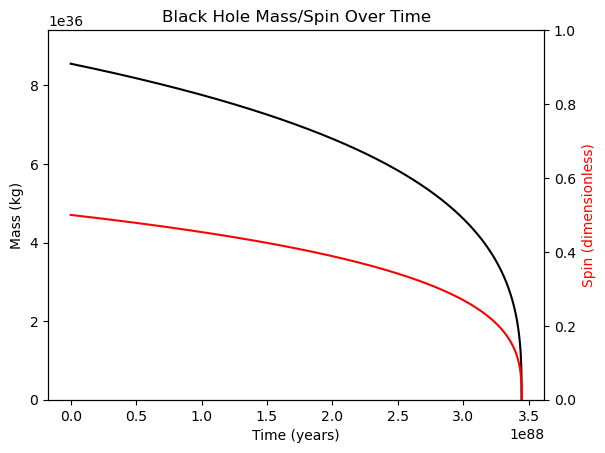

In [42]:
fig, ax1 = plt.subplots()

plt.title('Black Hole Mass/Spin Over Time')

ax1.plot(time(massdata), massdata, color='black')
ax1.invert_yaxis
ax1.set_ylim(0, blackholemass*1.1)
ax1.set_xlabel('Time (' + timeunits(et) + ')')
ax1.set_ylabel('Mass (kg)')

ax2 = ax1.twinx()
ax2.plot(time(spindata), spindata, color='red')
ax2.set_ylim(0, 1)
ax2.set_ylabel('Spin (dimensionless)', color="red")

Text(0, 0.5, 'Temp (K)')

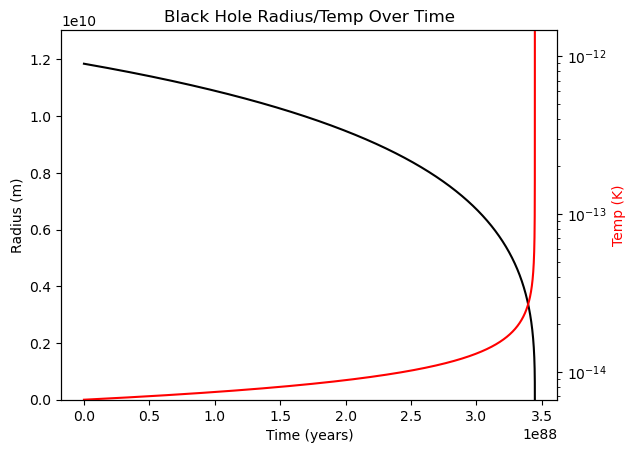

In [43]:
fig, ax3 = plt.subplots()

plt.title('Black Hole Radius/Temp Over Time')

raddata = raddata[1:]
ax3.plot(time(raddata), raddata, color='black')
ax3.set_ylim(0, max(raddata)*1.1)
ax3.set_xlabel('Time (' + timeunits(et) + ')') 
ax3.set_ylabel('Radius (m)')

tempdata = tempdata[2:]
ax4 = ax3.twinx()
ax4.plot(time(tempdata), tempdata, color='red')
ax4.set_ylim(tempdata[0], tempdata[-1])
ax4.set_yscale('log')
ax4.set_ylabel('Temp (K)', color="red")

In [44]:
# Initial Conditions Predictor

In [45]:
truemassdata = massdata.copy()

In [46]:
alldata = []
accuracydata = []
precision = predprecision

In [47]:
def predict(data):
    alldata.clear()
    accuracydata.clear()
    resetdata()

    truedata = data.copy()
    tmass = massmin
    tdata = []

    while tmass <= massmax: # Generates an array of predicted curves in a set range with a set precision
        resetdata()
        ts = (tmass**3)/precision
        evaptime(tmass, 0, ts)
        alldata.append(massdata.copy())
        tmass *= 10/grain 
            
    for i in alldata: # Calculates the difference between each item in the predicted curve and the original and saves it to accuracydata
        tdata.clear()
        for loc, j in enumerate(i):
            tdata.append(abs(truedata[loc] - j) / abs(truedata[loc]))
        accuracydata.append(tdata.copy()[1:])

In [48]:
def bestmatch(data):

    avgdata = []
    bestmatchloc = 0

    for i in data: # Takes the average difference of each point on a curve so each curve is represented by 1 accuracy value
        avg = 0
        for j in i:
            avg += j
        avgdata.append(avg/len(i))
    
    bestmatch = avgdata[0]
    
    for loc, i in enumerate(avgdata): # Sequentially finds the curve with the lowest difference and displays it as the new closest match
        if i < bestmatch:
            bestmatch = i
            bestmatchloc = loc - 1
            print("New best match: " + f"{massmin*(10/grain)**bestmatchloc:.2e}" + "kg")
        loc+=1
    return(bestmatch, bestmatchloc)

In [49]:
grain = 9 # Larger = more accuracy, DNE > 10 (log = 10/grain)
massmin = 1e34 # Smallest mass scanned
massmax = 1e38 # Largest mass scanned

inputdata = truemassdata

predict(inputdata)
best = bestmatch(accuracydata.copy())
closestmatch = ((10/grain)**(best[1]))*massmin
print('Closest match: ~' + f"{closestmatch:e}" + 'kg\nAccuracy: ' + str(100-(abs(100-round((closestmatch/blackholemass)*100)))) + '%')

New best match: 1.00e+34kg
New best match: 1.11e+34kg
New best match: 1.23e+34kg
New best match: 1.37e+34kg
New best match: 1.52e+34kg
New best match: 1.69e+34kg
New best match: 1.88e+34kg
New best match: 2.09e+34kg
New best match: 2.32e+34kg
New best match: 2.58e+34kg
New best match: 2.87e+34kg
New best match: 3.19e+34kg
New best match: 3.54e+34kg
New best match: 3.93e+34kg
New best match: 4.37e+34kg
New best match: 4.86e+34kg
New best match: 5.40e+34kg
New best match: 6.00e+34kg
New best match: 6.66e+34kg
New best match: 7.40e+34kg
New best match: 8.23e+34kg
New best match: 9.14e+34kg
New best match: 1.02e+35kg
New best match: 1.13e+35kg
New best match: 1.25e+35kg
New best match: 1.39e+35kg
New best match: 1.55e+35kg
New best match: 1.72e+35kg
New best match: 1.91e+35kg
New best match: 2.12e+35kg
New best match: 2.36e+35kg
New best match: 2.62e+35kg
New best match: 2.91e+35kg
New best match: 3.24e+35kg
New best match: 3.60e+35kg
New best match: 3.99e+35kg
New best match: 4.44e+35kg
N

(0.0, 8.5501888e+36)

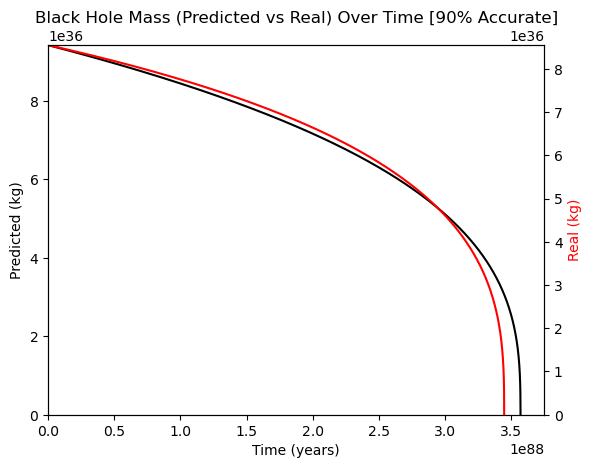

In [50]:
massdata.clear()
pet = evaptime(closestmatch, 0, (closestmatch**3)/precision)
predicted = massdata
real = truemassdata

fig, ax5 = plt.subplots()

plt.title('Black Hole Mass (Predicted vs Real) Over Time [' + str(100-(abs(100-round((closestmatch/blackholemass)*100)))) + '% Accurate]')
precision = predprecision
timestep = (closestmatch**3)/predprecision
ax5.plot(time(predicted), predicted, color='black')
ax5.set_ylabel('Predicted (kg)', color="black")
ax5.set_ylim(0, closestmatch)
ax5.set_xlabel('Time (' + timeunits(pet) + ')') 
ax5.set_xlim(0)

ax6 = ax5.twinx()
timestep = (blackholemass**3)/realprecision
ax6.plot(time(real), real, color='red')
ax6.set_ylabel('Real (kg)', color="red")
ax6.set_ylim(0, blackholemass)